# 01 – Môi trường thực hành và khảo sát dữ liệu

Notebook của thành viên A, gồm 4 phần:

- **A. Tổng quan môi trường:** phiên bản phần mềm, tài nguyên, cấu hình Spark.
- **B. Khảo sát bằng Pandas:** đọc `rating.csv` gốc, thống kê, kiểm tra null/trùng, phân phối điểm; khảo sát `movie`, `tag`.
- **C. Khảo sát bằng PySpark:** cùng file CSV gốc, minh họa lazy evaluation, thống kê, khảo sát người dùng/phim/thời gian.
- **D. So sánh Pandas và PySpark:** cùng một phép tính, bộ nhớ, bảng tổng hợp, biểu đồ.

**Vì sao `SIZE = "full"`?** Máy chạy có 17,6 GB RAM cấp cho Docker, đủ để Pandas nạp toàn bộ 20 triệu dòng
`rating.csv`. Phần khảo sát cần số liệu trên **toàn bộ dữ liệu** (số dòng, phân phối, thời gian đọc thật),
nên notebook này đặt `SIZE = "full"` thay vì `"sample"`. Máy 8 GB nên đổi về `"sample"` và cấu hình bộ nhớ nhỏ hơn.

**Cách đo thời gian:** dùng `time.perf_counter()`. Các phép đo dùng để so sánh được chạy 3 lần và lấy **trung vị**;
riêng Pandas đọc CSV chỉ đo 1 lần vì rất nặng.

## A. Tổng quan môi trường

### A.1. Khởi tạo SparkSession

Cell khởi tạo chung của nhóm (mục 4.6 kế hoạch), ở đây `SIZE = "full"`.

In [1]:
# ANH: 01_01 | Khởi tạo SparkSession
import time
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

# "sample" khi viết code, đổi thành "full" khi chạy số liệu cuối
SIZE = "full"
CSV  = "/home/jovyan/work/data/ml-20m"                    # CSV gốc (chỉ A dùng để so sánh)
DATA = f"/home/jovyan/work/data/ml-20m-parquet/{SIZE}"    # Parquet: B, C đọc từ đây

spark = (SparkSession.builder
         .appName("BigDataLab")
         .master("local[*]")                    # máy 8GB: "local[2]"
         .config("spark.driver.memory", "3g")   # máy 8GB: "2g"
         .config("spark.sql.shuffle.partitions", "8")
         .getOrCreate())
sc = spark.sparkContext

print("Spark version:", spark.version)
print("Số luồng song song:", sc.defaultParallelism)

Spark version: 4.2.0
Số luồng song song: 8


### A.2. Phiên bản phần mềm và tài nguyên

Phiên bản Java được lấy trực tiếp từ JVM mà Spark đang dùng; RAM là RAM mà container nhìn thấy (`/proc/meminfo`).

In [2]:
# ANH: 01_02 | Phiên bản phần mềm và tài nguyên
import os, sys, gc, statistics
import pandas as pd
import pyarrow
import pyspark

def ram_gb():
    with open("/proc/meminfo") as f:
        for line in f:
            if line.startswith("MemTotal:"):
                return int(line.split()[1]) / 1024**2      # kB -> GB

info = [
    ("Python",       sys.version.split()[0]),
    ("Pandas",       pd.__version__),
    ("PyArrow",      pyarrow.__version__),
    ("PySpark",      pyspark.__version__),
    ("Spark (JVM)",  spark.version),
    ("Java",         sc._jvm.System.getProperty("java.version")),
    ("Số CPU",       os.cpu_count()),
    ("RAM container", f"{ram_gb():.1f} GB"),
    ("Docker image", "quay.io/jupyter/pyspark-notebook:spark-4.2.0"),
]
for k, v in info:
    print(f"{k:<14}: {v}")

Python        : 3.13.16
Pandas        : 2.3.3
PyArrow       : 25.0.0
PySpark       : 4.2.0
Spark (JVM)   : 4.2.0
Java          : 21.0.12.1
Số CPU        : 8
RAM container : 17.6 GB
Docker image  : quay.io/jupyter/pyspark-notebook:spark-4.2.0


### A.3. Cấu hình Spark đang dùng

Chỉ in các khóa cấu hình quan trọng (không in toàn bộ `getAll()`).

In [3]:
# ANH: 01_03 | Cấu hình Spark đang dùng
conf = sc.getConf()
config = [
    ("master",                       sc.master),
    ("appName",                      sc.appName),
    ("spark.driver.memory",          conf.get("spark.driver.memory")),
    ("spark.sql.shuffle.partitions", spark.conf.get("spark.sql.shuffle.partitions")),
    ("defaultParallelism",           sc.defaultParallelism),
    ("uiWebUrl (trong container)",   sc.uiWebUrl),
    ("Spark UI (trên máy host)",     "http://localhost:4041"),
]
for k, v in config:
    print(f"{k:<30}: {v}")

master                        : local[*]
appName                       : BigDataLab
spark.driver.memory           : 3g
spark.sql.shuffle.partitions  : 8
defaultParallelism            : 8
uiWebUrl (trong container)    : http://0498aae6593a:4040
Spark UI (trên máy host)      : http://localhost:4041


### A.4. Giải thích các thành phần

- **SparkSession** là điểm vào duy nhất của Spark (từ Spark 2.0): dùng để đọc dữ liệu, tạo DataFrame, chạy SQL.
  **SparkContext** (`sc`) là đối tượng cấp thấp hơn nằm bên trong SparkSession, quản lý kết nối tới cluster và
  làm việc với RDD.
- **`local[*]`**: Spark chạy trên một máy, dùng số luồng bằng số lõi CPU (ở đây 8 luồng ⇒ xử lý song song tối đa
  8 task). `local[2]` nghĩa là chỉ dùng 2 luồng.
- **Driver và executor:** driver chạy chương trình chính, lập kế hoạch thực thi (chia job → stage → task);
  executor chạy các task trên từng phần dữ liệu (partition). Ở chế độ local, driver và executor **chạy chung một
  JVM** trong container, nên `spark.driver.memory` cũng là bộ nhớ cho xử lý dữ liệu.
- **Spark UI:** giao diện web theo dõi job, stage, task, bộ nhớ cache. Trong container Spark UI ở cổng 4040; file
  `docker-compose.yml` ánh xạ ra **http://localhost:4041** trên máy host (Jupyter: http://localhost:8889).
- **Docker:** cả nhóm dùng chung image `quay.io/jupyter/pyspark-notebook:spark-4.2.0` (có sẵn Python, Java,
  Spark, Pandas), nên môi trường trên 3 máy giống nhau. Thư mục dự án được **mount** vào `/home/jovyan/work`
  trong container: sửa file ở Windows thì container thấy ngay, dữ liệu và kết quả không mất khi xóa container.

**Nhận xét:** Môi trường chạy Python 3.13.16, Spark/PySpark 4.2.0, Java 21, Pandas 2.3.3 trong container có
8 CPU và 17,6 GB RAM. Spark chạy `local[*]` nên có 8 luồng song song (`defaultParallelism = 8`), driver được cấp 3 GB.
`uiWebUrl` hiện tên máy bên trong container (cổng 4040); trên máy host mở Spark UI ở http://localhost:4041.

## B. Khảo sát bằng Pandas (CSV gốc, bản full)

### B.1. Đọc `rating.csv`

Pandas đọc **toàn bộ** file vào RAM ngay lập tức (không lazy) và chỉ dùng 1 lõi CPU. Đo thời gian đọc (1 lần),
kích thước, kiểu dữ liệu và bộ nhớ thực tế (`memory_usage(deep=True)` tính cả chuỗi).

In [4]:
# ANH: 01_04 | Pandas: đọc rating.csv
t0 = time.perf_counter()
ratings_pd = pd.read_csv(f"{CSV}/rating.csv")
t_pd_read = time.perf_counter() - t0

pd_mem_mb = ratings_pd.memory_usage(deep=True).sum() / 1024**2
print(f"Thời gian đọc : {t_pd_read:.2f} s")
print(f"Shape         : {ratings_pd.shape}")
print(f"Bộ nhớ (deep) : {pd_mem_mb:,.1f} MB")
print()
print("Kiểu dữ liệu:")
print(ratings_pd.dtypes.to_string())

Thời gian đọc : 12.51 s
Shape         : (20000263, 4)
Bộ nhớ (deep) : 1,754.8 MB

Kiểu dữ liệu:
userId         int64
movieId        int64
rating       float64
timestamp     object


**Nhận xét:** Pandas đọc hết 20.000.263 dòng trong khoảng **12,5 s** và chiếm khoảng **1.755 MB RAM**, gấp
khoảng 2,7 lần dung lượng file CSV (658 MB). Nguyên nhân chính là cột `timestamp` được đọc thành kiểu `object` (mỗi giá
trị là một chuỗi Python riêng), còn các cột số dùng `int64`/`float64` 8 byte.

### B.2. Thống kê mô tả, null, trùng lặp, phân phối điểm

In [5]:
# ANH: 01_05 | Pandas: thống kê mô tả rating
print(ratings_pd.head().to_string())
print()
print(ratings_pd.describe().to_string(float_format=lambda x: f"{x:,.2f}"))

   userId  movieId  rating            timestamp
0       1        2     3.5  2005-04-02 23:53:47
1       1       29     3.5  2005-04-02 23:31:16
2       1       32     3.5  2005-04-02 23:33:39
3       1       47     3.5  2005-04-02 23:32:07
4       1       50     3.5  2005-04-02 23:29:40



             userId       movieId        rating
count 20,000,263.00 20,000,263.00 20,000,263.00
mean      69,045.87      9,041.57          3.53
std       40,038.63     19,789.48          1.05
min            1.00          1.00          0.50
25%       34,395.00        902.00          3.00
50%       69,141.00      2,167.00          3.50
75%      103,637.00      4,770.00          4.00
max      138,493.00    131,262.00          5.00


In [6]:
# ANH: 01_06 | Pandas: kiểm tra null và trùng lặp
print("Số giá trị null theo cột:")
print(ratings_pd.isnull().sum().to_string())
print()
print(f"Số dòng trùng toàn bộ           : {ratings_pd.duplicated().sum():,}")
print(f"Số cặp (userId, movieId) bị trùng: {ratings_pd.duplicated(subset=['userId', 'movieId']).sum():,}")

Số giá trị null theo cột:


userId       0
movieId      0
rating       0
timestamp    0



Số dòng trùng toàn bộ           : 0


Số cặp (userId, movieId) bị trùng: 0


In [7]:
# ANH: 01_07 | Pandas: phân phối điểm rating
pd_dist = ratings_pd["rating"].value_counts().sort_index()
dist_table = pd.DataFrame({"Số lượt": pd_dist, "Tỉ lệ (%)": pd_dist / pd_dist.sum() * 100})
print(dist_table.to_string(formatters={"Số lượt": "{:,}".format, "Tỉ lệ (%)": "{:.2f}".format}))
print(f"Tổng: {pd_dist.sum():,}")

         Số lượt Tỉ lệ (%)
rating                    
0.5      239,125      1.20
1.0      680,732      3.40
1.5      279,252      1.40
2.0    1,430,997      7.15
2.5      883,398      4.42
3.0    4,291,193     21.46
3.5    2,200,156     11.00
4.0    5,561,926     27.81
4.5    1,534,824      7.67
5.0    2,898,660     14.49
Tổng: 20,000,263


**Nhận xét:**
- Không có giá trị null, không có dòng trùng, mỗi cặp (userId, movieId) chỉ xuất hiện một lần ⇒ dữ liệu `rating` rất sạch.
- Điểm từ 0,5 đến 5,0, bước 0,5; trung bình khoảng **3,53**, trung vị 3,5.
- Điểm **4,0** phổ biến nhất (27,81%), tiếp theo là 3,0 (21,46%) và 5,0 (14,49%). Điểm nguyên được chọn nhiều hơn hẳn
  điểm lẻ (vd 4,5 chỉ có 7,67%); người dùng có xu hướng chấm cao (≥ 3,0 chiếm khoảng 82%).

### B.3. Khảo sát `movie.csv` và `tag.csv`

Hai bảng nhỏ: kiểm tra kích thước, null, phim không có thể loại (`(no genres listed)`), số thể loại khác nhau
(cột `genres` gồm nhiều thể loại nối bằng `|`), số tag rỗng.

In [8]:
# ANH: 01_08 | Pandas: khảo sát movie và tag
movies_pd = pd.read_csv(f"{CSV}/movie.csv")
tags_pd   = pd.read_csv(f"{CSV}/tag.csv")

genres = movies_pd["genres"].str.split("|").explode()
genres = genres[genres != "(no genres listed)"]

print(f"movie: shape {movies_pd.shape}")
print("  null theo cột:", movies_pd.isnull().sum().to_dict())
print(f"  phim '(no genres listed)': {(movies_pd['genres'] == '(no genres listed)').sum():,}")
print(f"  số thể loại khác nhau    : {genres.nunique()}")
import textwrap
print(textwrap.fill(", ".join(sorted(genres.unique())), width=80,
                    initial_indent="  các thể loại: ", subsequent_indent=" " * 16))
print()
print(f"tag: shape {tags_pd.shape}")
print("  null theo cột:", tags_pd.isnull().sum().to_dict())
n_empty = tags_pd["tag"].isnull().sum() + (tags_pd["tag"].astype(str).str.strip() == "").sum()
print(f"  tag rỗng (null hoặc chỉ khoảng trắng): {n_empty:,}")
print(f"  số tag khác nhau: {tags_pd['tag'].nunique():,}")

del movies_pd, tags_pd, genres
gc.collect();

movie: shape (27278, 3)
  null theo cột: {'movieId': 0, 'title': 0, 'genres': 0}
  phim '(no genres listed)': 246
  số thể loại khác nhau    : 19
  các thể loại: Action, Adventure, Animation, Children, Comedy, Crime,
                Documentary, Drama, Fantasy, Film-Noir, Horror, IMAX, Musical,
                Mystery, Romance, Sci-Fi, Thriller, War, Western

tag: shape (465564, 4)
  null theo cột: {'userId': 0, 'movieId': 0, 'tag': 16, 'timestamp': 0}
  tag rỗng (null hoặc chỉ khoảng trắng): 23
  số tag khác nhau: 38,643


**Nhận xét:** `movie` có 27.278 phim, không có null; 246 phim không có thể loại; có **19 thể loại** khác nhau.
`tag` có 465.564 dòng, 38.643 tag khác nhau; có 16 tag null (tổng cộng 23 tag rỗng hoặc chỉ có khoảng trắng). Đây là
những dòng cần lọc bỏ nếu phân tích theo tag.

## C. Khảo sát bằng PySpark (cùng file CSV gốc)

### C.1. Đọc CSV và lazy evaluation

Đọc `rating.csv` với `inferSchema=True` (Spark quét file để đoán kiểu) rồi `count()`. Chạy 3 lần, lấy trung vị.

Spark **lazy**: các phép biến đổi như `filter` chỉ ghi lại kế hoạch, chưa đọc dữ liệu; chỉ khi gọi **action**
(`count`, `show`, `collect`, …) Spark mới thực sự chạy. Cell dưới đo thời gian tạo `filter` so với thời gian
`count()` sau `filter`.

In [9]:
# ANH: 01_09 | PySpark: đọc CSV và lazy evaluation
def median_time(fn, n=3):
    """Chạy fn() n lần, trả về (trung vị thời gian, kết quả lần cuối)."""
    times, res = [], None
    for _ in range(n):
        t0 = time.perf_counter()
        res = fn()
        times.append(time.perf_counter() - t0)
    return statistics.median(times), res

def read_count_csv():
    df = spark.read.csv(f"{CSV}/rating.csv", header=True, inferSchema=True)
    return df, df.count()

t_sp_read, (ratings, n_rows) = median_time(read_count_csv)
print(f"Đọc CSV + count (trung vị 3 lần): {t_sp_read:.2f} s")
print(f"Số dòng: {n_rows:,}   Số cột: {len(ratings.columns)}")
print(f"Số partition: {ratings.rdd.getNumPartitions()}")
print()

# Lazy evaluation
def make_filter():
    return ratings.filter(F.col("rating") >= 4.5)
t_filter, high = median_time(make_filter)
t_count, n_high = median_time(lambda: high.count())
print("Lazy evaluation (trung vị 3 lần):")
print(f"  tạo filter(rating >= 4.5) : {t_filter * 1000:.2f} ms  (chưa đọc dữ liệu)")
print(f"  count() sau filter        : {t_count:.2f} s   -> {n_high:,} dòng")

Đọc CSV + count (trung vị 3 lần): 6.24 s
Số dòng: 20,000,263   Số cột: 4
Số partition: 8



Lazy evaluation (trung vị 3 lần):
  tạo filter(rating >= 4.5) : 10.40 ms  (chưa đọc dữ liệu)
  count() sau filter        : 3.13 s   -> 4,433,484 dòng


**Nhận xét:** Spark đọc CSV (có `inferSchema`) + đếm mất khoảng **6,2 s** (trung vị), nhanh hơn Pandas đọc
CSV (12,5 s) vì đọc song song 8 partition trên 8 luồng. Tạo `filter` chỉ mất khoảng **10 ms**, vì Spark mới ghi lại kế hoạch;
đến khi gọi `count()` Spark mới đọc file và lọc, mất khoảng **3,1 s** (4.433.484 dòng có điểm ≥ 4,5). Đây là
**lazy evaluation**.

### C.2. Schema, thống kê mô tả, null, trùng lặp, phân phối điểm

In [10]:
# ANH: 01_10 | PySpark: schema và dữ liệu mẫu
ratings.printSchema()
ratings.show(5)

root
 |-- userId: integer (nullable = true)
 |-- movieId: integer (nullable = true)
 |-- rating: double (nullable = true)
 |-- timestamp: timestamp (nullable = true)



+------+-------+------+-------------------+
|userId|movieId|rating|          timestamp|
+------+-------+------+-------------------+
|     1|      2|   3.5|2005-04-02 23:53:47|
|     1|     29|   3.5|2005-04-02 23:31:16|
|     1|     32|   3.5|2005-04-02 23:33:39|
|     1|     47|   3.5|2005-04-02 23:32:07|
|     1|     50|   3.5|2005-04-02 23:29:40|
+------+-------+------+-------------------+
only showing top 5 rows


In [11]:
# ANH: 01_11 | PySpark: thống kê mô tả
ratings.describe().show()

+-------+-----------------+------------------+------------------+
|summary|           userId|           movieId|            rating|
+-------+-----------------+------------------+------------------+
|  count|         20000263|          20000263|          20000263|
|   mean|69045.87258292554| 9041.567330339605|3.5255285642993797|
| stddev|40038.62665316145|19789.477445413166|1.0519889192942444|
|    min|                1|                 1|               0.5|
|    max|           138493|            131262|               5.0|
+-------+-----------------+------------------+------------------+



In [12]:
# ANH: 01_12 | PySpark: kiểm tra null và trùng lặp
print("Số giá trị null theo cột:")
ratings.select([F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in ratings.columns]).show()

n_distinct_rows = ratings.distinct().count()
n_distinct_pair = ratings.select("userId", "movieId").distinct().count()
print(f"Số dòng trùng toàn bộ           : {n_rows - n_distinct_rows:,}")
print(f"Số cặp (userId, movieId) bị trùng: {n_rows - n_distinct_pair:,}")

Số giá trị null theo cột:


+------+-------+------+---------+
|userId|movieId|rating|timestamp|
+------+-------+------+---------+
|     0|      0|     0|        0|
+------+-------+------+---------+



Số dòng trùng toàn bộ           : 0
Số cặp (userId, movieId) bị trùng: 0


In [13]:
# ANH: 01_13 | PySpark: phân phối điểm
sp_dist = (ratings.groupBy("rating").count()
                  .withColumn("ti_le_pct", F.round(F.col("count") / n_rows * 100, 2))
                  .orderBy("rating"))
sp_dist.show()

# So sánh với kết quả Pandas ở mục B.2
sp_dist_pd = sp_dist.toPandas().set_index("rating")["count"]
match = sp_dist_pd.sort_index().astype("int64").equals(pd_dist.sort_index().astype("int64"))
print("So với Pandas:", "KHỚP" if match else "KHÔNG KHỚP")

+------+-------+---------+
|rating|  count|ti_le_pct|
+------+-------+---------+
|   0.5| 239125|      1.2|
|   1.0| 680732|      3.4|
|   1.5| 279252|      1.4|
|   2.0|1430997|     7.15|
|   2.5| 883398|     4.42|
|   3.0|4291193|    21.46|
|   3.5|2200156|     11.0|
|   4.0|5561926|    27.81|
|   4.5|1534824|     7.67|
|   5.0|2898660|    14.49|
+------+-------+---------+



So với Pandas: KHỚP


**Nhận xét:** `inferSchema` đoán đúng kiểu: `userId`, `movieId` là `integer` (Pandas dùng `int64`), `rating` là
`double`, và `timestamp` được nhận là kiểu **timestamp** (Pandas để `object`). Thống kê mô tả, số null (0), số dòng trùng (0)
và phân phối điểm của Spark **khớp hoàn toàn** với Pandas.

### C.3. Khảo sát người dùng, phim và thời gian

Khoảng thời gian của dữ liệu, số người dùng, số phim được đánh giá, số phim trong `movie.csv` chưa có lượt
đánh giá nào (dùng `left_anti` join), và số lượt đánh giá ít nhất/nhiều nhất của một người dùng.

In [14]:
# ANH: 01_14 | PySpark: khảo sát người dùng, phim và thời gian
ts = F.to_timestamp("timestamp")
s = ratings.agg(F.year(F.min(ts)).alias("nam_dau"),
                F.year(F.max(ts)).alias("nam_cuoi"),
                F.countDistinct("userId").alias("so_user"),
                F.countDistinct("movieId").alias("so_phim_co_rating")).first()

movies = spark.read.csv(f"{CSV}/movie.csv", header=True, inferSchema=True)
n_movies = movies.count()
n_no_rating = movies.join(ratings.select("movieId").distinct(), "movieId", "left_anti").count()

per_user = ratings.groupBy("userId").count()
u = per_user.agg(F.min("count").alias("min"), F.max("count").alias("max"),
                 F.round(F.avg("count"), 1).alias("avg")).first()

print(f"Khoảng thời gian              : {s.nam_dau} – {s.nam_cuoi}")
print(f"Số người dùng                 : {s.so_user:,}")
print(f"Số phim trong movie.csv       : {n_movies:,}")
print(f"Số phim có ít nhất 1 rating   : {s.so_phim_co_rating:,}")
print(f"Số phim không có rating nào   : {n_no_rating:,}")
print(f"Số rating của một user: ít nhất {u['min']:,}, nhiều nhất {u['max']:,}, trung bình {u['avg']:,}")

Khoảng thời gian              : 1995 – 2015
Số người dùng                 : 138,493
Số phim trong movie.csv       : 27,278
Số phim có ít nhất 1 rating   : 26,744
Số phim không có rating nào   : 534
Số rating của một user: ít nhất 20, nhiều nhất 9,254, trung bình 144.4


**Nhận xét:** Dữ liệu trải từ năm **1995 đến 2015**, có **138.493 người dùng** và **26.744 phim** được đánh
giá. **534 phim** trong `movie.csv` chưa có lượt đánh giá nào. Mỗi người dùng có ít nhất **20** lượt (MovieLens chỉ giữ
người dùng có từ 20 lượt trở lên), nhiều nhất **9.254** lượt, trung bình khoảng 144 lượt ⇒ phân bố rất lệch.

## D. So sánh Pandas và PySpark

### D.1. Cùng một phép tính

Tính điểm trung bình và số lượt đánh giá theo `movieId`, giữ phim có **ít nhất 1000 lượt**, lấy 10 phim điểm cao
nhất (cùng điểm thì xếp theo `movieId` tăng dần để kết quả xác định). Đo 3 lần, lấy trung vị:

- **Pandas:** trên DataFrame đã nạp sẵn trong RAM (không tính thời gian đọc).
- **Spark CSV:** đọc lại `rating.csv` (inferSchema) + tính toán.
- **Spark Parquet:** đọc `DATA/rating` (Parquet full) + tính toán.

Phép tính phải đọc toàn bộ cột `movieId` và `rating`, nên đây là so sánh công bằng hơn so với `count()`.

In [15]:
# ANH: 01_15 | Cùng một phép tính: Pandas và PySpark
def top10_pandas():
    g = ratings_pd.groupby("movieId")["rating"].agg(avg_rating="mean", n_ratings="count")
    g = g[g["n_ratings"] >= 1000].reset_index()
    return g.sort_values(["avg_rating", "movieId"], ascending=[False, True]).head(10)

def top10_spark(df):
    return (df.groupBy("movieId")
              .agg(F.avg("rating").alias("avg_rating"), F.count("*").alias("n_ratings"))
              .filter(F.col("n_ratings") >= 1000)
              .orderBy(F.desc("avg_rating"), "movieId")
              .limit(10)
              .toPandas())

t_pd_top, top_pd = median_time(top10_pandas)
t_csv_top, top_csv = median_time(
    lambda: top10_spark(spark.read.csv(f"{CSV}/rating.csv", header=True, inferSchema=True)))
t_pq_top, top_pq = median_time(lambda: top10_spark(spark.read.parquet(f"{DATA}/rating")))

print("Thời gian (trung vị 3 lần):")
print(f"  Pandas (dữ liệu đã nạp) : {t_pd_top:6.2f} s")
print(f"  Spark đọc CSV           : {t_csv_top:6.2f} s")
print(f"  Spark đọc Parquet       : {t_pq_top:6.2f} s")
print()

def same(a, b):
    return (list(a["movieId"]) == list(b["movieId"])
            and list(a["n_ratings"]) == list(b["n_ratings"])
            and (a["avg_rating"].round(9).values == b["avg_rating"].round(9).values).all())
print("Top 10 Pandas = Spark CSV    :", "GIỐNG" if same(top_pd.reset_index(drop=True), top_csv) else "KHÁC")
print("Top 10 Pandas = Spark Parquet:", "GIỐNG" if same(top_pd.reset_index(drop=True), top_pq) else "KHÁC")
print()

titles = spark.read.parquet(f"{DATA}/movie").toPandas()
out = top_pq.merge(titles[["movieId", "title"]], on="movieId", how="left")
out["avg_rating"] = out["avg_rating"].round(3)
w = out["title"].str.len().max()
print(out[["movieId", "title", "avg_rating", "n_ratings"]].to_string(
    index=False, justify="left", formatters={"title": lambda s: s.ljust(w)}))

Thời gian (trung vị 3 lần):
  Pandas (dữ liệu đã nạp) :   0.34 s
  Spark đọc CSV           :   9.13 s
  Spark đọc Parquet       :   0.85 s

Top 10 Pandas = Spark CSV    : GIỐNG
Top 10 Pandas = Spark Parquet: GIỐNG



 movieId title                                          avg_rating  n_ratings
 318     Shawshank Redemption, The (1994)              4.447       63366     
 858     Godfather, The (1972)                         4.365       41355     
  50     Usual Suspects, The (1995)                    4.334       47006     
 527     Schindler's List (1993)                       4.310       50054     
1221     Godfather: Part II, The (1974)                4.276       27398     
2019     Seven Samurai (Shichinin no samurai) (1954)   4.274       11611     
 904     Rear Window (1954)                            4.271       17449     
7502     Band of Brothers (2001)                       4.263        4305     
 912     Casablanca (1942)                             4.258       24349     
 922     Sunset Blvd. (a.k.a. Sunset Boulevard) (1950) 4.257        6525     


**Nhận xét:**
- Kết quả top 10 của Pandas và Spark (cả CSV và Parquet) **giống hệt nhau**; đứng đầu là *Shawshank Redemption* (4,447 điểm,
  63.366 lượt).
- Khi dữ liệu đã nằm sẵn trong RAM, Pandas tính rất nhanh (**0,34 s**). Nhưng muốn có dữ liệu đó, Pandas phải đọc CSV mất
  12,5 s và giữ 1,75 GB RAM.
- Spark tính trọn cả đọc + tính toán: từ CSV mất **9,1 s**, từ Parquet chỉ **0,85 s** (nhanh hơn khoảng 11 lần). Phép tính
  này phải đọc thật toàn bộ cột `movieId`, `rating`, nên đây là so sánh công bằng giữa CSV và Parquet (khác với `count()`).

### D.2. Bộ nhớ

- **Pandas:** bộ nhớ của DataFrame `rating` đã đo ở mục B.1 (`memory_usage(deep=True)`).
- **Spark:** `cache()` bảng `rating` từ Parquet, gọi `count()` để cache thật sự được tạo, rồi đọc kích thước cache
  từ `getRDDStorageInfo()` (cùng số liệu với tab *Storage* của Spark UI). Spark cache ở dạng cột có nén.
- Kèm dung lượng file trên đĩa của CSV và Parquet.

In [16]:
# ANH: 01_16 | So sánh bộ nhớ
def dir_size(path):
    return sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(path) for f in fs)

MB = 1024**2
rating_pq = spark.read.parquet(f"{DATA}/rating").cache()
rating_pq.count()

spark_cache_mb = None
try:
    infos = sc._jsc.sc().getRDDStorageInfo()
    mem = sum(i.memSize() for i in infos)
    disk = sum(i.diskSize() for i in infos)
    if mem + disk > 0:
        spark_cache_mb = mem / MB
        print(f"Spark cache: {len(infos)} RDD, trong RAM {mem / MB:,.1f} MB, trên đĩa {disk / MB:,.1f} MB")
except Exception as e:
    print("Không đọc được getRDDStorageInfo():", type(e).__name__, e)

if spark_cache_mb is None:
    print("Không lấy được kích thước cache của Spark -> bỏ qua số liệu này.")

csv_mb = os.path.getsize(f"{CSV}/rating.csv") / MB
pq_mb  = dir_size(f"{DATA}/rating") / MB
print()
print(f"{'Hạng mục':<38}{'MB':>10}")
print(f"{'rating.csv trên đĩa':<38}{csv_mb:>10,.1f}")
print(f"{'rating Parquet (full) trên đĩa':<38}{pq_mb:>10,.1f}")
print(f"{'Pandas DataFrame trong RAM (deep)':<38}{pd_mem_mb:>10,.1f}")
print(f"{'Spark cache (Parquet rating) trong RAM':<38}"
      + (f"{spark_cache_mb:>10,.1f}" if spark_cache_mb is not None else f"{'không đo được':>10}"))

rating_pq.unpersist()
del ratings_pd
gc.collect();

Spark cache: 1 RDD, trong RAM 337.5 MB, trên đĩa 0.0 MB

Hạng mục                                      MB
rating.csv trên đĩa                        658.4
rating Parquet (full) trên đĩa             171.2
Pandas DataFrame trong RAM (deep)        1,754.8
Spark cache (Parquet rating) trong RAM     337.5


**Nhận xét:** Cùng bảng `rating`, Pandas cần khoảng **1.755 MB** RAM, còn Spark cache (dạng cột, có nén) chỉ
khoảng **338 MB**, ít hơn khoảng 5 lần. Trên đĩa, Parquet (171 MB) nhỏ hơn CSV (658 MB) khoảng 3,8 lần. Ngoài ra Spark
không bắt buộc nạp hết dữ liệu vào RAM: khi không cache, Spark đọc và xử lý từng partition.

### D.3. Bảng tổng hợp

In [17]:
# ANH: 01_17 | Bảng so sánh Pandas và PySpark
cache_txt = f"cache {spark_cache_mb:,.0f} MB (Parquet)" if spark_cache_mb is not None else "không đo được"
summary = pd.DataFrame([
    ("Đọc rating.csv",            f"{t_pd_read:.1f} s (1 lần)",   f"{t_sp_read:.1f} s (đọc + count)"),
    ("Top 10 phim (mục D.1)",     f"{t_pd_top:.1f} s (đã nạp)",  f"CSV {t_csv_top:.1f} s / Parquet {t_pq_top:.1f} s"),
    ("Bộ nhớ chứa rating",        f"{pd_mem_mb:,.0f} MB",         cache_txt),
    ("Cách thực thi",             "Chạy ngay",                    "Lazy, chờ action"),
    ("Chạy song song/phân tán",   "Không (1 lõi)",                f"Có ({sc.defaultParallelism} luồng, mở rộng ra cluster)"),
    ("Nên dùng khi",              "Dữ liệu vừa RAM một máy",      "Dữ liệu lớn, cần mở rộng"),
], columns=["Tiêu chí", "Pandas", "PySpark"])
widths = {c: max(len(c), summary[c].str.len().max()) for c in summary.columns}
print(summary.to_string(index=False, justify="left",
                        formatters={c: (lambda w: lambda s: s.ljust(w))(widths[c]) for c in summary.columns}))

Tiêu chí                Pandas                  PySpark                         
Đọc rating.csv          12.5 s (1 lần)          6.2 s (đọc + count)             
Top 10 phim (mục D.1)   0.3 s (đã nạp)          CSV 9.1 s / Parquet 0.9 s       
Bộ nhớ chứa rating      1,755 MB                cache 338 MB (Parquet)          
Cách thực thi           Chạy ngay               Lazy, chờ action                
Chạy song song/phân tán Không (1 lõi)           Có (8 luồng, mở rộng ra cluster)
Nên dùng khi            Dữ liệu vừa RAM một máy Dữ liệu lớn, cần mở rộng        


### D.4. Biểu đồ

Font mặc định của matplotlib (DejaVu Sans) có đủ chữ tiếng Việt nên không cần đổi font.

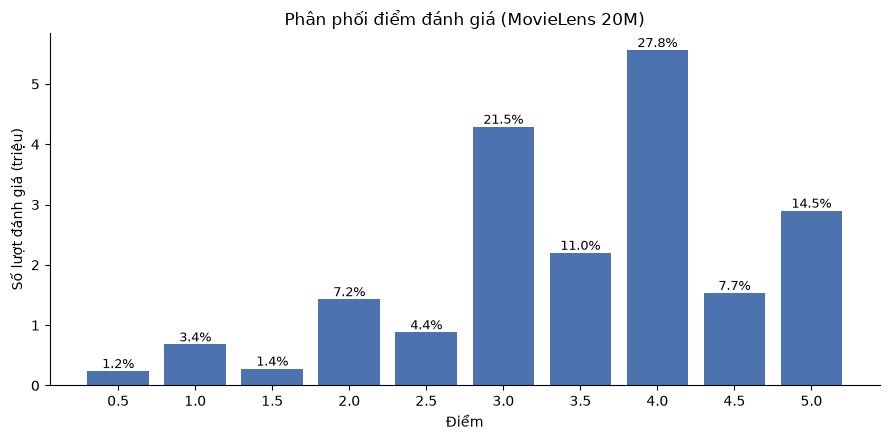

In [18]:
# ANH: 01_18 | Biểu đồ phân phối điểm
import matplotlib.pyplot as plt

dist = sp_dist.toPandas()
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(dist["rating"].astype(str), dist["count"] / 1e6, color="#4C72B0")
for x, (c, p) in enumerate(zip(dist["count"], dist["ti_le_pct"])):
    ax.text(x, c / 1e6, f"{p:.1f}%", ha="center", va="bottom", fontsize=9)
ax.set_title("Phân phối điểm đánh giá (MovieLens 20M)")
ax.set_xlabel("Điểm")
ax.set_ylabel("Số lượt đánh giá (triệu)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

Năm nhiều lượt nhất: 2000 (1,953,659 lượt); năm ít nhất: 1995 (4 lượt)


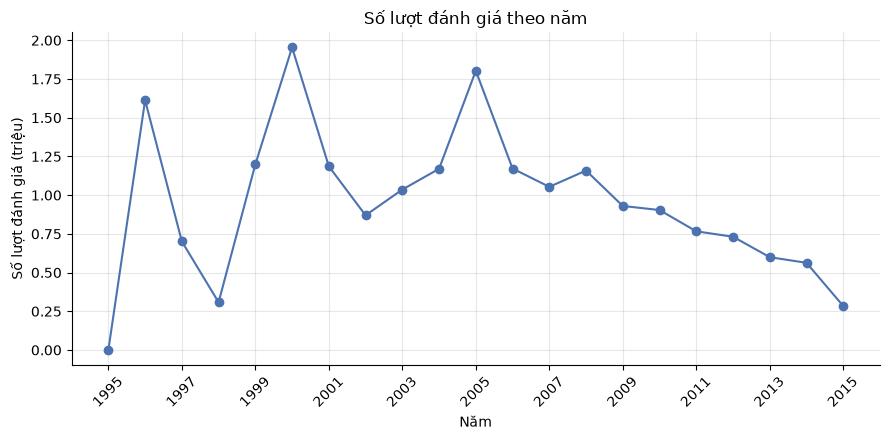

In [19]:
# ANH: 01_19 | Số lượt rating theo năm
by_year = (ratings.groupBy(F.year(F.to_timestamp("timestamp")).alias("nam"))
                  .count().orderBy("nam").toPandas())
peak = by_year.loc[by_year["count"].idxmax()]
print(f"Năm nhiều lượt nhất: {int(peak['nam'])} ({int(peak['count']):,} lượt); "
      f"năm ít nhất: {int(by_year.loc[by_year['count'].idxmin(), 'nam'])} "
      f"({by_year['count'].min():,} lượt)")
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(by_year["nam"], by_year["count"] / 1e6, marker="o", color="#4C72B0")
ax.set_title("Số lượt đánh giá theo năm")
ax.set_xlabel("Năm")
ax.set_ylabel("Số lượt đánh giá (triệu)")
ax.set_xticks(by_year["nam"][::2])
ax.tick_params(axis="x", rotation=45)
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Nhận xét:** Biểu đồ phân phối cho thấy rõ điểm 4,0 và 3,0 chiếm ưu thế, điểm lẻ ít hơn điểm nguyên kề bên.
Số lượt đánh giá theo năm biến động mạnh: cao nhất năm **2000** (khoảng 1,95 triệu lượt), có các đỉnh phụ vào 1996 và 2005,
và giảm dần sau 2008. Năm 1995 chỉ có 4 lượt; năm 2015 thấp vì dữ liệu chỉ thu thập đến tháng 3/2015.

## Kết luận

1. **Môi trường:** Docker image `pyspark-notebook:spark-4.2.0` cung cấp sẵn Spark 4.2.0, Java 21, Python 3.13; Spark
   chạy `local[*]` với 8 luồng, driver 3 GB, Spark UI ở http://localhost:4041.
2. **Chất lượng dữ liệu:** `rating` có 20.000.263 dòng, không null, không trùng; 138.493 người dùng, 26.744 phim được đánh
   giá, giai đoạn 1995–2015. Điểm 4,0 phổ biến nhất, điểm trung bình khoảng 3,53. `tag` có 16 giá trị null cần lọc.
3. **Đọc dữ liệu:** Spark đọc CSV song song nhanh hơn Pandas (khoảng 6,2 s so với 12,5 s). Riêng thời gian `count()` trên
   Parquet (notebook 00) rất nhỏ một phần nhờ Spark **lấy số dòng từ metadata** của file Parquet chứ không đọc dữ liệu;
   vì vậy phép tính ở mục D.1 mới là so sánh công bằng: Parquet 0,85 s so với CSV 9,1 s (khoảng 11 lần).
4. **Bộ nhớ:** Pandas cần khoảng 1,75 GB RAM cho `rating`, Spark cache dạng cột chỉ khoảng 338 MB.
5. **Lazy evaluation:** biến đổi (`filter`) gần như tức thì (khoảng 10 ms), Spark chỉ chạy khi có action (`count` khoảng 3,1 s).
6. **Khi nào dùng gì:** **Pandas** phù hợp khi dữ liệu vừa RAM của một máy và cần thao tác nhanh, tương tác (khi đã nạp, phép
   tính chỉ mất 0,34 s). **Spark** phù hợp khi dữ liệu lớn hơn RAM, cần xử lý song song/phân tán hoặc mở rộng ra cluster,
   và nên kết hợp với định dạng cột như Parquet.

*Thời gian đo trên máy A, có thể khác giữa các lần chạy (file đã nằm trong cache của hệ điều hành hay chưa) và giữa các máy;
chỉ nên dùng để so sánh tương đối.*

In [20]:
spark.stop()